In [ ]:
!pip install -q pypdf pandas numpy matplotlib seaborn
!pip install -q tiktoken google-genai
!pip install -q sentence-transformers faiss-cpu

In [ ]:
import os
import re
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pypdf import PdfReader
from google.colab import files
import tiktoken
print("All libraries imported")

All libraries imported


In [ ]:
uploaded = files.upload()
pdf_path = next(iter(uploaded.keys()))
print("Uploaded file:", pdf_path)

Saving 1nplea2023001.pdf to 1nplea2023001.pdf
Uploaded file: 1nplea2023001.pdf


In [ ]:
reader = PdfReader(pdf_path)
document_pages = []
for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""
    document_pages.append({
        "page_number": page_number,
        "raw_text": text
    })
print("Total PDF pages:", len(document_pages))
total_chars = sum(
    len(page["raw_text"]) for page in document_pages
)
print("Total extracted characters:", total_chars)
print("\nSample extracted text:")
print(document_pages[6]["raw_text"][:2000])

Total PDF pages: 134
Total extracted characters: 338643

Sample extracted text:
 
 
 
 
NEPAL 
STAFF REPORT FOR THE 2023 ARTICLE IV CONSULTATION, 
FIRST AND SECOND REVIEWS UNDER THE EXTENDED 
CREDIT FACILITY ARRANGEMENT, REQUESTS FOR 
WAIVERS OF NONOBSERVANCE OF PERFORMANCE 
CRITERIA, EXTENSION OF THE ARRANGEMENT, AND 
REPHASING OF DISBURSEMENTS 
EXECUTIVE SUMMARY 
Context. Global developments have impacted Nepal’s import-dependent economy—
particularly through higher commodity prices. The current account weakened and 
reserves declined in the first half of 2022. Pressure on reserves has subsided since then, 
thanks in part to monetary policy tightening and cooling domestic demand, but 
inflation remains elevated. Fiscal policy has been less expansionary than projected, but a 
recent fall in revenues is adding to near-term fiscal pressures. Non-performing loans are 
increasing, while capital adequacy ratios remain above regulatory minima. Risks are on 
the downside. 
Program developmen

In [ ]:
def clean_text(text):
    text = text.replace("\x00", " ")
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{3,}', '\n\n', text)
    text = re.sub(r'(?m)^\s*\d+\s*$', '', text)
    return text.strip()
for page in document_pages:
    page["clean_text"] = clean_text(page["raw_text"])
print("Text cleaning completed.")
print(document_pages[6]["clean_text"][:2000])

Text cleaning completed.
NEPAL 
STAFF REPORT FOR THE 2023 ARTICLE IV CONSULTATION, 
FIRST AND SECOND REVIEWS UNDER THE EXTENDED 
CREDIT FACILITY ARRANGEMENT, REQUESTS FOR 
WAIVERS OF NONOBSERVANCE OF PERFORMANCE 
CRITERIA, EXTENSION OF THE ARRANGEMENT, AND 
REPHASING OF DISBURSEMENTS 
EXECUTIVE SUMMARY 
Context. Global developments have impacted Nepal’s import-dependent economy—
particularly through higher commodity prices. The current account weakened and 
reserves declined in the first half of 2022. Pressure on reserves has subsided since then, 
thanks in part to monetary policy tightening and cooling domestic demand, but 
inflation remains elevated. Fiscal policy has been less expansionary than projected, but a 
recent fall in revenues is adding to near-term fiscal pressures. Non-performing loans are 
increasing, while capital adequacy ratios remain above regulatory minima. Risks are on 
the downside. 
Program developments. The ECF has helped mitigate the impact of the pandemic and 

In [ ]:
encoding = tiktoken.get_encoding("cl100k_base")
CHUNK_SIZE = 400
CHUNK_OVERLAP = 50
chunks = []
for page in document_pages:
    text = page["clean_text"]
    if not text:
        continue
    tokens = encoding.encode(text)
    start = 0
    while start < len(tokens):
        end = min(start + CHUNK_SIZE, len(tokens))
        chunk_tokens = tokens[start:end]
        chunk_text = encoding.decode(chunk_tokens)
        chunks.append({
            "chunk_id": len(chunks) + 1,
            "page_number": page["page_number"],
            "start_token": start,
            "end_token": end,
            "token_count": len(chunk_tokens),
            "text": chunk_text
        })
        if end == len(tokens):
            break
        start = end - CHUNK_OVERLAP
chunks_df = pd.DataFrame(chunks)
print("Total chunks:", len(chunks_df))
print("Average tokens per chunk:",
      round(chunks_df["token_count"].mean(), 2))
display(chunks_df.head())

Total chunks: 287
Average tokens per chunk: 308.77


,chunk_id,page_number,start_token,end_token,token_count,text
0,1,1,0,400,400,IMF Country Report No. 23/158 \nNEPAL \nSTAFF ...
1,2,1,350,415,65,s of the IMF and the World Bank. \n• A Stateme...
2,3,2,0,136,136,© 2023 International Monetary Fund \n \nThe IM...
3,4,3,0,400,400,PR23/131 \n \nIMF Executive Board Concludes 20...
4,5,3,350,659,309,6) in an amount equivalent to SDR 282.42 milli...


In [ ]:
os.makedirs("data", exist_ok=True)
with open("data/nepal_extracted_pages.json", "w") as f:
    json.dump(document_pages, f, indent=4)
with open("data/nepal_chunks.json", "w") as f:
    json.dump(chunks, f, indent=4)
chunks_df.to_csv("data/nepal_chunks.csv", index=False)
print("Extraction and chunking files saved successfully!")

Extraction and chunking files saved successfully!


In [ ]:
CHUNK_SIZE = 400
CHUNK_OVERLAP = 50

all_tokens = []
token_pages = []

for page in document_pages:

    page_tokens = encoding.encode(page["clean_text"])

    all_tokens.extend(page_tokens)

    token_pages.extend(
        [page["page_number"]] * len(page_tokens)
    )

chunks = []

start = 0
chunk_id = 1

while start < len(all_tokens):

    end = min(start + CHUNK_SIZE, len(all_tokens))

    chunk_tokens = all_tokens[start:end]

    chunk_text = encoding.decode(chunk_tokens)

    chunks.append({
        "chunk_id": chunk_id,
        "start_page": token_pages[start],
        "end_page": token_pages[end - 1],
        "start_token": start,
        "end_token": end,
        "token_count": len(chunk_tokens),
        "text": chunk_text
    })

    chunk_id += 1

    if end == len(all_tokens):
        break

    start = end - CHUNK_OVERLAP

chunks_df = pd.DataFrame(chunks)

print("Total document tokens:", len(all_tokens))
print("Total chunks:", len(chunks_df))
print("Average chunk size:",
      round(chunks_df["token_count"].mean(), 2))
print("Minimum chunk size:",
      chunks_df["token_count"].min())
print("Maximum chunk size:",
      chunks_df["token_count"].max())

display(chunks_df.head())

Total document tokens: 80966
Total chunks: 232
Average chunk size: 398.78
Minimum chunk size: 116
Maximum chunk size: 400


,chunk_id,start_page,end_page,start_token,end_token,token_count,text
0,1,1,1,0,400,400,IMF Country Report No. 23/158 \nNEPAL \nSTAFF ...
1,2,1,3,350,750,400,s of the IMF and the World Bank. \n• A Stateme...
2,3,3,3,700,1100,400,require preserving macroeconomic stability an...
3,4,3,4,1050,1450,400,the context of the post-COVID-19 recovery and...
4,5,4,4,1400,1800,400,percent of GDP in FY2022/23 due to weaker imp...


In [ ]:
with open("data/nepal_chunks.json", "w") as f:
    json.dump(chunks, f, indent=4)

chunks_df.to_csv(
    "data/nepal_chunks.csv",
    index=False
)

print("Improved chunk files saved successfully!")

Improved chunk files saved successfully!


# INtegrating GEMINI AI

In [ ]:
from google import genai
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini API configured successfully!")

Gemini API configured successfully!


In [ ]:
available_models = list(client.models.list())
for model in available_models:
    if "generateContent" in (model.supported_actions or []):
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models

In [ ]:
PRIMARY_MODEL = "models/gemini-3.6-flash"
EVALUATOR_MODEL = "models/gemini-3.8-flash"
print("Primary model:", PRIMARY_MODEL)
print("Evaluator model:", EVALUATOR_MODEL)

Primary model: models/gemini-3.6-flash
Evaluator model: models/gemini-3.8-flash


In [ ]:
response = client.models.generate_content(
    model=PRIMARY_MODEL,
    contents="Summarise the importance of financial stability in Nepal in three bullet points."
)

print(response.text)

Here is a summary of the importance of financial stability in Nepal in three bullet points:

* **Drives Economic Growth and Infrastructure Development:** A stable financial system builds investor confidence, attracts Foreign Direct Investment (FDI), and mobilizes domestic savings to fund critical growth sectors such as hydropower, tourism, and infrastructure.
* **Mitigates External Shocks and Protects Remittances:** It protects Nepal's import-dependent economy from global market volatility, preserves foreign exchange reserves, and ensures the safe, efficient inflow and utilization of vital remittance income.
* **Fosters Public Trust and Poverty Alleviation:** Stability in the banking, cooperative, and microfinance sectors protects the savings of everyday citizens, strengthens financial inclusion, and supports small businesses, helping to reduce poverty across the country.


In [ ]:
import time
import json
import os

def summarise_chunk_batch(batch, batch_number):

    context = ""

    for item in batch:
        context += (
            f"\n[Chunk ID: {item['chunk_id']}] "
            f"[Pages: {item['start_page']}-{item['end_page']}]\n"
            f"{item['text']}\n"
        )

    prompt = f"""
You are an economic research analyst working with an IMF Country Report.

Analyse the following extracted text from the IMF Nepal 2023 Article IV Consultation report.

Extract:
1. Main economic developments.
2. GDP growth and inflation findings.
3. Monetary and fiscal policy developments.
4. Banking and financial stability issues.
5. External sector developments.
6. Economic risks and vulnerabilities.
7. IMF policy recommendations.

Requirements:
- Use only the supplied source text.
- Do not introduce external information.
- Preserve numerical values and reporting periods.
- Distinguish historical figures from forecasts.
- Do not invent missing information.
- Include relevant source page numbers.
- Avoid repeating information unnecessarily.

Return a concise, structured analytical summary.

SOURCE TEXT:
{context}
"""

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=PRIMARY_MODEL,
                contents=prompt
            )

            return {
                "batch_id": batch_number,
                "summary": response.text,
                "chunk_ids": [x["chunk_id"] for x in batch]
            }

        except Exception as e:
            if attempt == 2:
                return {
                    "batch_id": batch_number,
                    "summary": None,
                    "error": str(e),
                    "chunk_ids": [x["chunk_id"] for x in batch]
                }

            time.sleep(5 * (attempt + 1))

In [ ]:
chunk_records = []
for _, row in chunks_df.iterrows():
    start_page = row.get("start_page", row.get("page_number", 0))
    end_page = row.get("end_page", start_page)
    chunk_records.append({
        "chunk_id": int(row["chunk_id"]),
        "start_page": int(start_page),
        "end_page": int(end_page),
        "text": row["text"]
    })
BATCH_SIZE = 8
chunk_batches = [
    chunk_records[i:i + BATCH_SIZE]
    for i in range(0, len(chunk_records), BATCH_SIZE)
]
print("Total chunks:", len(chunk_records))
print("Total summarisation batches:", len(chunk_batches))

Total chunks: 232
Total summarisation batches: 29


In [ ]:
for i, batch in enumerate(chunk_batches):

    batch_number = i + 1

    if batch_number in completed_ids:
        continue

    result = summarise_chunk_batch(batch, batch_number)

    batch_summaries.append(result)

    with open("data/summaries/chunk_summaries.json", "w") as f:
        json.dump(batch_summaries, f, indent=4)

    if result.get("summary"):
        completed_ids.add(batch_number)

    print(f"Completed batch {batch_number}/29")

Completed batch 4/29
Completed batch 5/29
Completed batch 6/29
Completed batch 7/29
Completed batch 8/29
Completed batch 9/29
Completed batch 10/29
Completed batch 11/29
Completed batch 12/29
Completed batch 13/29
Completed batch 14/29
Completed batch 15/29
Completed batch 16/29
Completed batch 17/29
Completed batch 18/29
Completed batch 19/29
Completed batch 20/29
Completed batch 21/29
Completed batch 22/29
Completed batch 23/29
Completed batch 24/29
Completed batch 25/29
Completed batch 26/29
Completed batch 27/29
Completed batch 28/29
Completed batch 29/29


In [ ]:
import json
import os
summary_path = "data/summaries/chunk_summaries.json"
with open(summary_path, "r", encoding="utf-8") as f:
    batch_summaries = json.load(f)
print("Total saved batches:", len(batch_summaries))
for item in batch_summaries:
    batch_id = item.get("batch_id", "Unknown")
    summary = item.get("summary", "")
    status = "Successful" if summary and str(summary).strip() else "Empty or failed"
    print(f"Batch {batch_id}: {status}")
successful = sum(
    1 for item in batch_summaries
    if item.get("summary") and str(item["summary"]).strip()
)
print("\nSuccessful summaries:", successful)
print("Missing or empty summaries:", len(batch_summaries) - successful)

Total saved batches: 29
Batch 1: Successful
Batch 2: Successful
Batch 3: Successful
Batch 4: Successful
Batch 5: Successful
Batch 6: Successful
Batch 7: Successful
Batch 8: Successful
Batch 9: Successful
Batch 10: Successful
Batch 11: Successful
Batch 12: Successful
Batch 13: Successful
Batch 14: Successful
Batch 15: Successful
Batch 16: Successful
Batch 17: Successful
Batch 18: Successful
Batch 19: Successful
Batch 20: Successful
Batch 21: Empty or failed
Batch 22: Empty or failed
Batch 23: Empty or failed
Batch 24: Empty or failed
Batch 25: Empty or failed
Batch 26: Empty or failed
Batch 27: Empty or failed
Batch 28: Empty or failed
Batch 29: Empty or failed

Successful summaries: 20
Missing or empty summaries: 9


In [ ]:
os.makedirs("data/backup", exist_ok=True)
with open("data/backup/nepal_chunk_summaries.json", "w", encoding="utf-8") as f:
    json.dump(batch_summaries, f, indent=4, ensure_ascii=False)
print("Backup saved successfully.")

Backup saved successfully.


In [ ]:
failed_batches = []
for item in batch_summaries:
    summary = item.get("summary", "")
    if not summary or not str(summary).strip():
        failed_batches.append(item.get("batch_id"))
print("Failed batch IDs:", failed_batches)
print("Number of failed batches:", len(failed_batches))

Failed batch IDs: [21, 22, 23, 24, 25, 26, 27, 28, 29]
Number of failed batches: 9


In [ ]:
for batch_number in failed_batches:
    batch = chunk_batches[batch_number - 1]
    print(f"Retrying batch {batch_number}/29")
    result = summarise_chunk_batch(batch, batch_number)
    for i, existing in enumerate(batch_summaries):
        if existing.get("batch_id") == batch_number:
            batch_summaries[i] = result
            break
    with open("data/summaries/chunk_summaries.json", "w", encoding="utf-8") as f:
        json.dump(batch_summaries, f, indent=4, ensure_ascii=False)
    print(f"Batch {batch_number} saved")

Retrying batch 21/29
Batch 21 saved
Retrying batch 22/29
Batch 22 saved
Retrying batch 23/29
Batch 23 saved
Retrying batch 24/29
Batch 24 saved
Retrying batch 25/29
Batch 25 saved
Retrying batch 26/29
Batch 26 saved
Retrying batch 27/29
Batch 27 saved
Retrying batch 28/29
Batch 28 saved
Retrying batch 29/29
Batch 29 saved


In [ ]:
successful = sum(
    1 for item in batch_summaries
    if item.get("summary") and str(item["summary"]).strip()
)
print("Successful batches:", successful)
print("Failed batches:", 29 - successful)

Successful batches: 20
Failed batches: 9


In [ ]:
for item in batch_summaries:
    batch_id = item.get("batch_id")
    if batch_id in range(21, 30):
        print("\nBatch:", batch_id)
        print("Keys:", list(item.keys()))
        print("Content:", str(item)[:1200])


Batch: 21
Keys: ['batch_id', 'summary', 'error', 'chunk_ids']
Content: {'batch_id': 21, 'summary': None, 'error': "429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\\nPlease retry in 1h52m35.764488474s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations'

In [ ]:
print(summarise_chunk_batch.__name__)
print(batch_summaries[0])

summarise_chunk_batch
{'batch_id': 1, 'summary': "Here is a structured analytical summary based strictly on the provided IMF report excerpt.\n\n---\n\n### 1. Main Economic Developments\n* **Economic Overview:** Following a post-pandemic recovery, Nepal’s economic growth softened due to global shocks (including Russia’s war in Ukraine and elevated commodity prices) and necessary domestic policy adjustments [Pages 1-3, 3-3, 4-5].\n* **IMF ECF Program Status:** \n  * The Extended Credit Facility (ECF) arrangement was approved on January 12, 2022, for SDR 282.42 million (approx. US$384.8 million) [Pages 3-3].\n  * Completion of the first and second reviews under the ECF allowed an immediate disbursement of SDR 39.20 million (approx. US$52.8 million), bringing total disbursements for budget support to SDR 117.70 million (approx. US$157.4 million) [Pages 1-3, 3-3].\n  * Program performance was mixed, with progress continuing but at a slower-than-desired pace in a challenging environment [Pag

In [ ]:
successful_summaries = [
    item for item in batch_summaries
    if item.get("summary") and str(item["summary"]).strip()
]

with open("data/summaries/nepal_successful_summaries.json", "w", encoding="utf-8") as f:
    json.dump(successful_summaries, f, indent=4, ensure_ascii=False)

print("Saved successful summaries:", len(successful_summaries))

Saved successful summaries: 20


In [ ]:
response = client.models.generate_content(
    model=PRIMARY_MODEL,
    contents="Reply with: API connection successful."
)
print(response.text)

API connection successful.


In [ ]:
import json
with open("data/summaries/nepal_successful_summaries.json", "r", encoding="utf-8") as f:
    successful_summaries = json.load(f)
batch_summaries = successful_summaries.copy()
completed_ids = {
    item["batch_id"]
    for item in batch_summaries
}
failed_batches = [
    i + 1 for i in range(len(chunk_batches))
    if i + 1 not in completed_ids
]
print("Completed batches:", len(completed_ids))
print("Remaining batches:", failed_batches)

Completed batches: 20
Remaining batches: [21, 22, 23, 24, 25, 26, 27, 28, 29]


In [ ]:
import time
import json
for batch_number in failed_batches:
    batch = chunk_batches[batch_number - 1]
    print(f"Processing batch {batch_number}/29")
    result = summarise_chunk_batch(batch, batch_number)
    if result.get("summary") and str(result["summary"]).strip():
        batch_summaries.append(result)
        with open("data/summaries/chunk_summaries.json", "w", encoding="utf-8") as f:
            json.dump(batch_summaries, f, indent=4, ensure_ascii=False)
        print(f"Batch {batch_number} completed successfully")
    else:
        print(f"Batch {batch_number} failed:", result.get("error"))
    time.sleep(2)

Processing batch 21/29
Batch 21 completed successfully
Processing batch 22/29
Batch 22 completed successfully
Processing batch 23/29
Batch 23 completed successfully
Processing batch 24/29
Batch 24 completed successfully
Processing batch 25/29
Batch 25 completed successfully
Processing batch 26/29
Batch 26 completed successfully
Processing batch 27/29
Batch 27 completed successfully
Processing batch 28/29
Batch 28 completed successfully
Processing batch 29/29
Batch 29 completed successfully


In [ ]:
print("Successful batches:", len(batch_summaries))
print("Missing batches:", [
    i for i in range(1, 30)
    if i not in {item["batch_id"] for item in batch_summaries}
])

Successful batches: 29
Missing batches: []


In [ ]:
import json
with open("data/summaries/chunk_summaries.json", "r", encoding="utf-8") as f:
    batch_summaries = json.load(f)
successful_ids = {
    item["batch_id"]
    for item in batch_summaries
    if item.get("summary") and str(item["summary"]).strip()
}
missing_ids = [
    i for i in range(1, 30)
    if i not in successful_ids
]
print("Total batches:", len(batch_summaries))
print("Successful summaries:", len(successful_ids))
print("Missing batches:", missing_ids)

Total batches: 29
Successful summaries: 29
Missing batches: []


In [ ]:
with open("data/summaries/nepal_all_29_summaries.json", "w", encoding="utf-8") as f:
    json.dump(batch_summaries, f, indent=4, ensure_ascii=False)
print("All 29 summaries backed up successfully.")

All 29 summaries backed up successfully.


In [ ]:
import json
import tiktoken
import os

with open("data/summaries/nepal_all_29_summaries.json", "r", encoding="utf-8") as f:
    batch_summaries = json.load(f)

batch_summaries = sorted(batch_summaries, key=lambda x: x["batch_id"])

combined_input = "\n\n".join(
    f"BATCH {item['batch_id']}\n{item['summary']}"
    for item in batch_summaries
)

encoding = tiktoken.get_encoding("cl100k_base")
input_tokens = len(encoding.encode(combined_input))

print("Total batches:", len(batch_summaries))
print("Combined input tokens:", input_tokens)
print("Combined text characters:", len(combined_input))

os.makedirs("data/consolidated", exist_ok=True)

with open("data/consolidated/nepal_combined_summaries.txt", "w", encoding="utf-8") as f:
    f.write(combined_input)

print("Combined input saved successfully.")

Total batches: 29
Combined input tokens: 48594
Combined text characters: 192016
Combined input saved successfully.


In [ ]:
import json
import os
import time
GROUP_SIZE = 5
summary_groups = [
    batch_summaries[i:i + GROUP_SIZE]
    for i in range(0, len(batch_summaries), GROUP_SIZE)
]
print("Total groups:", len(summary_groups))
for i, group in enumerate(summary_groups):
    print(
        f"Group {i + 1}: "
        f"Batches {group[0]['batch_id']}–{group[-1]['batch_id']}"
    )
os.makedirs("data/consolidated", exist_ok=True)

Total groups: 6
Group 1: Batches 1–5
Group 2: Batches 6–10
Group 3: Batches 11–15
Group 4: Batches 16–20
Group 5: Batches 21–25
Group 6: Batches 26–29


In [ ]:
def consolidate_summary_group(group, group_number):

    group_text = "\n\n".join(
        f"Batch {item['batch_id']}:\n{item['summary']}"
        for item in group
    )

    prompt = f"""
You are an IMF economic research analyst.

Consolidate the following summaries extracted from the IMF Nepal Country Report No. 23/158.

Produce a structured analytical summary covering:

1. Main economic developments
2. GDP growth and economic outlook
3. Inflation and price developments
4. Monetary and fiscal policy
5. Banking and financial stability
6. External sector and balance of payments
7. Sovereign debt and fiscal sustainability
8. Economic risks and vulnerabilities
9. IMF policy recommendations

Requirements:
- Use only information in the supplied summaries.
- Preserve all important numerical values and financial years.
- Distinguish historical values, estimates and forecasts.
- Retain source page references wherever provided.
- Do not invent missing indicators or figures.
- Identify repeated findings and remove unnecessary duplication.
- Clearly state when information is unavailable.
- Use concise academic language.

Source summaries:

{group_text}
"""

    try:
        response = client.models.generate_content(
            model=PRIMARY_MODEL,
            contents=prompt
        )

        return {
            "group_id": group_number,
            "source_batches": [
                item["batch_id"] for item in group
            ],
            "summary": response.text
        }

    except Exception as e:
        return {
            "group_id": group_number,
            "source_batches": [
                item["batch_id"] for item in group
            ],
            "summary": None,
            "error": str(e)
        }

In [ ]:
group_summaries = []

for i, group in enumerate(summary_groups):

    group_number = i + 1

    print(f"Processing group {group_number}/6")

    result = consolidate_summary_group(group, group_number)

    if result.get("summary"):
        group_summaries.append(result)

        with open(
            "data/consolidated/nepal_group_summaries.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                group_summaries,
                f,
                indent=4,
                ensure_ascii=False
            )

        print(f"Group {group_number} completed successfully")

    else:
        print(f"Group {group_number} failed:", result.get("error"))
        break

    time.sleep(2)

print("Completed groups:", len(group_summaries))

Processing group 1/6
Group 1 completed successfully
Processing group 2/6
Group 2 completed successfully
Processing group 3/6
Group 3 completed successfully
Processing group 4/6
Group 4 completed successfully
Processing group 5/6
Group 5 completed successfully
Processing group 6/6
Group 6 completed successfully
Completed groups: 6


In [ ]:
import json
import os

with open("data/consolidated/nepal_group_summaries.json", "r", encoding="utf-8") as f:
    group_summaries = json.load(f)

group_summaries = sorted(group_summaries, key=lambda x: x["group_id"])

group_text = "\n\n".join(
    f"GROUP {item['group_id']}\n{item['summary']}"
    for item in group_summaries
)

print("Groups available:", len(group_summaries))
print("Input characters:", len(group_text))

Groups available: 6
Input characters: 100409


In [ ]:
final_prompt = f"""
You are a senior economic research analyst preparing an executive summary
of IMF Country Report No. 23/158 on Nepal.

Use the six consolidated group summaries below.

Prepare a comprehensive but concise academic executive summary with these sections:

1. Economic Overview
2. GDP Growth and Economic Outlook
3. Inflation and Price Stability
4. Monetary and Fiscal Policy
5. Banking and Financial Sector Stability
6. External Sector Developments
7. Sovereign Debt and Fiscal Sustainability
8. Key Economic Strengths
9. Major Vulnerabilities and Risks
10. IMF Policy Recommendations

Requirements:
- Use only the supplied source summaries.
- Preserve numerical values, units and financial years accurately.
- Distinguish historical data, estimates and forecasts.
- Include source page references wherever available.
- Avoid duplicate findings.
- Do not invent values or unsupported conclusions.
- Clearly identify information that is unavailable.
- Use formal academic language.
- Highlight the main economic trends and their implications.

Consolidated source material:

{group_text}
"""

response = client.models.generate_content(
    model=PRIMARY_MODEL,
    contents=final_prompt
)

final_executive_summary = response.text

print(final_executive_summary)

# Executive Summary: IMF Country Report No. 23/158 (Nepal)

---

### 1. Economic Overview

Nepal’s economy demonstrated a strong post-pandemic recovery in FY2021/22, supported by robust domestic credit expansion, policy relaxation, and a resurgence in tourism [Group 4, p. 60; Group 6, pp. 114, 130–131]. However, this expansion triggered severe external pressures, which were subsequently compounded by global shocks—including Russia’s war in Ukraine, international commodity price spikes (particularly in food and fuel), global monetary tightening, and a strong U.S. dollar [Group 1, pp. 1–3, 6–7; Group 2, pp. 34, 36; Group 3, pp. 51–52; Group 6, pp. 113–114].

To stem rapid foreign exchange reserve losses, domestic authorities implemented monetary policy tightening alongside temporary administrative import controls between December 2021 and April 2022. These measures included mandatory Letters of Credit (LC), cash margins (15%–100%), and outright import bans on luxury goods [Group 1, pp. 1

In [ ]:
with open(
    "data/consolidated/nepal_final_executive_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(final_executive_summary)

print("Final executive summary saved successfully.")

Final executive summary saved successfully.


In [ ]:
themes = [
    "Inflation & Prices",
    "Interest Rates & Credit",
    "Housing & Real Estate",
    "Banking Capital & Liquidity",
    "Sovereign Debt",
    "Labor Market Dynamics",
    "Systemic Financial Risk"
]

print("Themes to analyse:", len(themes))

for i, theme in enumerate(themes, 1):
    print(f"{i}. {theme}")

Themes to analyse: 7
1. Inflation & Prices
2. Interest Rates & Credit
3. Housing & Real Estate
4. Banking Capital & Liquidity
5. Sovereign Debt
6. Labor Market Dynamics
7. Systemic Financial Risk


In [ ]:
def extract_theme(theme):

    prompt = f"""
You are an economic research analyst studying IMF Country Report No. 23/158 on Nepal.

Extract findings specifically related to this theme:

{theme}

Use the consolidated Nepal executive summary below as your source.

Return the following structure:

THEME:
Provide the theme name.

KEY FINDINGS:
Identify 4 to 7 important findings.

NUMERICAL INDICATORS:
List each relevant numerical indicator, value, unit and financial year.

HISTORICAL TRENDS:
Describe changes over time using available evidence.

POSITIVE DEVELOPMENTS:
Identify strengths or improvements.

VULNERABILITIES:
Identify risks, weaknesses or challenges.

IMPLICATIONS:
Explain what the findings indicate about Nepal's economy.

SOURCE REFERENCES:
Retain the available source page references.

IMPORTANT:
- Use only the supplied source material.
- Do not invent statistics.
- Use null or state unavailable when numerical data is missing.
- Distinguish historical values from estimates and forecasts.
- If the source does not provide enough evidence for a theme, explicitly state this.
- Avoid repeating unrelated information.

SOURCE MATERIAL:

{final_executive_summary}
"""

    response = client.models.generate_content(
        model=PRIMARY_MODEL,
        contents=prompt
    )

    return {
        "theme": theme,
        "analysis": response.text
    }

In [ ]:
import json
import os
import time

os.makedirs("data/thematic_analysis", exist_ok=True)

theme_results_path = "data/thematic_analysis/nepal_thematic_analysis.json"

if os.path.exists(theme_results_path):
    with open(theme_results_path, "r", encoding="utf-8") as f:
        theme_results = json.load(f)
else:
    theme_results = []

completed_themes = {
    item["theme"] for item in theme_results
    if item.get("analysis")
}

for theme in themes:

    if theme in completed_themes:
        print(f"Already completed: {theme}")
        continue

    print(f"Processing: {theme}")

    try:
        result = extract_theme(theme)

        if result.get("analysis"):
            theme_results.append(result)

            with open(theme_results_path, "w", encoding="utf-8") as f:
                json.dump(
                    theme_results,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

            completed_themes.add(theme)
            print(f"Completed: {theme}")

        else:
            print(f"Empty response: {theme}")

    except Exception as e:
        print(f"Failed: {theme}")
        print(str(e))
        break

    time.sleep(2)

print("\nCompleted themes:", len(completed_themes))
print("Remaining themes:", [
    theme for theme in themes
    if theme not in completed_themes
])

Processing: Inflation & Prices
Completed: Inflation & Prices
Processing: Interest Rates & Credit
Completed: Interest Rates & Credit
Processing: Housing & Real Estate
Completed: Housing & Real Estate
Processing: Banking Capital & Liquidity
Completed: Banking Capital & Liquidity
Processing: Sovereign Debt
Completed: Sovereign Debt
Processing: Labor Market Dynamics
Failed: Labor Market Dynamics
429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 1h26m22.994936915s.', 'status

In [ ]:
for item in theme_results:
    print("\n" + "=" * 65)
    print("THEME:", item["theme"])
    print("=" * 65)
    print(item["analysis"][:1200])


THEME: Inflation & Prices
THEME:
Inflation & Prices

KEY FINDINGS:
1. Inflation accelerated sharply in FY2021/22 and early FY2022/23 due to the pass-through of global food and fuel price spikes, peaking at 8.4%–8.6% in September 2022.
2. Price pressures began to ease in early 2023, with inflation moderating to 7.9% in February 2023 and 7.4% in mid-March 2023.
3. FY2022/23 period average inflation is projected at 7.8% (end-of-period 7.1%), gradually converging toward the Nepal Rastra Bank’s (NRB) target of 7.0%.
4. Over the medium term, inflation is projected to decline to 6.3% in FY2023/24, 5.6% in FY2024/25, and stabilize between 5.0%–5.4% over FY2025/26–FY2027/28.
5. The long-standing currency peg to the Indian rupee (fixed at NRs 1.6 per INR) serves as the primary nominal anchor for price stability in Nepal.
6. Domestic monetary tightening, slowing domestic demand, lower inflation in India, and softening global commodity prices are the main drivers behind the recent disinflation.
7

In [ ]:
import json

with open(
    "data/thematic_analysis/nepal_thematic_analysis.json",
    "r",
    encoding="utf-8"
) as f:
    theme_results = json.load(f)

print("Total themes saved:", len(theme_results))

for item in theme_results:
    analysis = item.get("analysis", "")
    print(
        item["theme"],
        "| Characters:", len(analysis),
        "| Status:", "Successful" if analysis.strip() else "Empty"
    )

Total themes saved: 5
Inflation & Prices | Characters: 5001 | Status: Successful
Interest Rates & Credit | Characters: 7989 | Status: Successful
Housing & Real Estate | Characters: 5081 | Status: Successful
Banking Capital & Liquidity | Characters: 4455 | Status: Successful
Sovereign Debt | Characters: 5454 | Status: Successful


In [ ]:
with open(
    "data/thematic_analysis/nepal_all_thematic_findings.txt",
    "w",
    encoding="utf-8"
) as f:

    for item in theme_results:
        f.write("=" * 80 + "\n")
        f.write(item["theme"] + "\n")
        f.write("=" * 80 + "\n\n")
        f.write(item["analysis"] + "\n\n")

print("Complete thematic findings saved.")

Complete thematic findings saved.


In [ ]:
completed_themes = {
    item["theme"] for item in theme_results
    if item.get("analysis")
}

remaining_themes = [
    theme for theme in themes
    if theme not in completed_themes
]

print("Completed themes:", len(completed_themes))
print("Remaining themes:", remaining_themes)

Completed themes: 5
Remaining themes: ['Labor Market Dynamics', 'Systemic Financial Risk']


In [ ]:
import json
import time

for theme in remaining_themes:

    print("Processing:", theme)

    try:
        result = extract_theme(theme)

        if result.get("analysis"):

            theme_results.append(result)

            with open(
                "data/thematic_analysis/nepal_thematic_analysis.json",
                "w",
                encoding="utf-8"
            ) as f:
                json.dump(
                    theme_results,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

            print("Completed:", theme)

        else:
            print("Empty response:", theme)

    except Exception as e:
        print("Error:", str(e))
        break

    time.sleep(2)

print("Total completed:", len(theme_results))

Processing: Labor Market Dynamics
Completed: Labor Market Dynamics
Processing: Systemic Financial Risk
Completed: Systemic Financial Risk
Total completed: 7


In [ ]:
with open(
    "data/thematic_analysis/nepal_thematic_analysis.json",
    "r",
    encoding="utf-8"
) as f:
    theme_results = json.load(f)

print("Total themes:", len(theme_results))

for item in theme_results:
    print(item["theme"], len(item["analysis"]))

Total themes: 7
Inflation & Prices 5001
Interest Rates & Credit 7989
Housing & Real Estate 5081
Banking Capital & Liquidity 4455
Sovereign Debt 5454
Labor Market Dynamics 3718
Systemic Financial Risk 8113


In [ ]:
import json
import os

with open(
    "data/thematic_analysis/nepal_thematic_analysis.json",
    "r",
    encoding="utf-8"
) as f:
    theme_results = json.load(f)

theme_text = "\n\n".join(
    f"THEME: {item['theme']}\n{item['analysis']}"
    for item in theme_results
)

indicator_source = final_executive_summary + "\n\n" + theme_text

print("Thematic analyses:", len(theme_results))
print("Source characters:", len(indicator_source))

Thematic analyses: 7
Source characters: 66540


In [ ]:
indicator_prompt = f"""
You are a financial data extraction specialist.

Extract the following indicators for Nepal from the supplied IMF report
analysis.

Return ONLY valid JSON using exactly this structure:

{{
    "country_name": "Nepal",
    "gdp_growth_forecast_pct": null,
    "headline_inflation_rate_pct": null,
    "central_bank_policy_rate_pct": null,
    "non_performing_loan_ratio": null,
    "unemployment_rate_pct": null,
    "tier_1_capital_ratio": null
}}

Rules:

1. Use numerical values only for available indicators.
2. Use null when the indicator is unavailable.
3. Do not invent, estimate or calculate missing values.
4. GDP growth must represent the FY2022/23 forecast.
5. Headline inflation must represent the FY2022/23 forecast.
6. Central bank policy rate must be the actual policy rate if explicitly available.
7. NPL ratio must use the latest reported figure available in the source.
8. Unemployment rate must be explicitly supported by the source.
9. Tier 1 capital ratio must use the latest reported figure available.
10. Do not confuse the Tier 1 capital ratio with total regulatory capital adequacy.
11. Add no extra fields or explanatory text.

SOURCE MATERIAL:

{indicator_source}
"""

print("Indicator extraction prompt prepared.")

Indicator extraction prompt prepared.


In [ ]:
response = client.models.generate_content(
    model=PRIMARY_MODEL,
    contents=indicator_prompt
)

print(response.text)

{
    "country_name": "Nepal",
    "gdp_growth_forecast_pct": 4.4,
    "headline_inflation_rate_pct": 7.8,
    "central_bank_policy_rate_pct": null,
    "non_performing_loan_ratio": 2.6,
    "unemployment_rate_pct": null,
    "tier_1_capital_ratio": 10.2
}


In [ ]:
import re
import json

json_text = response.text.strip()
json_text = re.sub(r"^```json\s*", "", json_text)
json_text = re.sub(r"\s*```$", "", json_text)

indicators = json.loads(json_text)

with open(
    "data/thematic_analysis/nepal_indicators.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(indicators, f, indent=4, ensure_ascii=False)

print(json.dumps(indicators, indent=4))
print("Indicator JSON saved successfully.")

{
    "country_name": "Nepal",
    "gdp_growth_forecast_pct": 4.4,
    "headline_inflation_rate_pct": 7.8,
    "central_bank_policy_rate_pct": null,
    "non_performing_loan_ratio": 2.6,
    "unemployment_rate_pct": null,
    "tier_1_capital_ratio": 10.2
}
Indicator JSON saved successfully.


In [ ]:
EVALUATOR_MODEL = "models/gemini-3.6-flash"

evaluation_response = client.models.generate_content(
    model=EVALUATOR_MODEL,
    contents=evaluation_prompt
)

indicator_evaluation = evaluation_response.text
print(indicator_evaluation)

### Evaluation Table of Extracted Indicators

| Indicator Key | Extracted Value | Factual Correctness | Numerical Accuracy | Reporting Period / Context | Unit & Interpretation | Justification of Null / Evaluation |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **`country_name`** | `"Nepal"` | **Correct** | N/A | Current / Report Scope | String | Fully correct. Matches source material subject. |
| **`gdp_growth_forecast_pct`** | `4.4` | **Correct** | **Accurate** (Lower bound) | FY2022/23 (Forecast) | Percent (%) Real GDP growth | **Accurate.** The source projects FY2022/23 growth at 4.4%–4.5%. Extracting 4.4% captures the baseline forecast floor. |
| **`headline_inflation_rate_pct`** | `7.8` | **Correct** | **Accurate** | FY2022/23 (Projected Period Average) | Percent (%) CPI Inflation | **Accurate.** Represents **projected period-average inflation** for FY2022/23 (end-of-period projection is 7.1%). |
| **`central_bank_policy_rate_pct`** | `null` | **Correct** | N/A | H2 FY2021/

In [ ]:
import time
for attempt in range(4):
    try:
        evaluation_response = client.models.generate_content(
            model=EVALUATOR_MODEL,
            contents=evaluation_prompt
        )
        indicator_evaluation = evaluation_response.text
        print(indicator_evaluation)
        break
    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
        if attempt < 3:
            time.sleep(20 * (attempt + 1))

Here is the data quality evaluation of the extracted indicators against the provided IMF Nepal report analysis.

---

### Indicator Evaluation Table

| Indicator | Extracted Value | Status | Target Period / Context | Evaluation Notes |
| :--- | :--- | :--- | :--- | :--- |
| **country_name** | `"Nepal"` | **Correct** | Ongoing | Matches source report context perfectly. |
| **gdp_growth_forecast_pct** | `4.4` | **Correct** | FY2022/23 (Forecast) | Source states FY22/23 real GDP growth is projected at **4.4%–4.5%**. The extracted value of `4.4` represents the lower bound of the forecast range. |
| **headline_inflation_rate_pct**| `7.8` | **Correct** | FY2022/23 (Forecast, Period Average) | Accurately extracted. Source specifies FY22/23 projected **period average** CPI inflation is **7.8%** (distinguished from end-of-period inflation of 7.1%). |
| **central_bank_policy_rate_pct**| `null` | **Correct (Justified)** | FY2021/22–FY2022/23 | The text notes a cumulative policy rate *increase* of

In [ ]:
with open("data/thematic_analysis/nepal_indicator_evaluation.txt", "w", encoding="utf-8") as f:
    f.write(indicator_evaluation)

print("Indicator evaluation saved successfully.")

Indicator evaluation saved successfully.


In [ ]:
qualitative_prompt = f"""
You are an economic research analyst.

Using only the supplied IMF Nepal report analysis, identify:

1. Economic strengths and growth drivers.
2. Economic vulnerabilities and challenges.

For each category, provide a maximum of 7 points.

Each point must contain:
- finding
- supporting_evidence
- economic_implication
- source_reference

Avoid repeating the same finding.
Do not invent statistics or facts.
If evidence is insufficient, state that clearly.

Return valid JSON using this structure:

{{
    "economic_strengths": [],
    "economic_vulnerabilities": []
}}

SOURCE MATERIAL:
{indicator_source}
"""

qualitative_response = client.models.generate_content(
    model=PRIMARY_MODEL,
    contents=qualitative_prompt
)

qualitative_results = qualitative_response.text
print(qualitative_results)

```json
{
    "economic_strengths": [
        {
            "finding": "Resilient workers' remittance inflows serve as a crucial external balance buffer and support domestic liquidity.",
            "supporting_evidence": "Remittances averaged 22.4% of GDP between 2017 and 2021, reached USD 8,325 million (20.7% of GDP) in FY2021/22, and surged 33.5% y-o-y in February 2023. This expansion helped lower central bank Standing Liquidity Facility (SLF) usage from ~NPR 700 billion to NPR 126 billion in December 2022.",
            "economic_implication": "Remittances stabilize the current account, cushion foreign exchange reserves, boost disposable income, and alleviate banking sector liquidity stress.",
            "source_reference": "Group 1, pp. 3-4, 6-6; Group 2, pp. 36-37; Group 4, p. 77; Group 6, pp. 114-115"
        },
        {
            "finding": "Expansion of domestic hydroelectric power generation improves energy independence and supports growth.",
            "supporting_evide

In [ ]:
qualitative_data = json.loads(
    qualitative_results.replace("```json", "").replace("```", "").strip()
)

with open("data/thematic_analysis/nepal_qualitative_analysis.json", "w", encoding="utf-8") as f:
    json.dump(qualitative_data, f, indent=4, ensure_ascii=False)

print("Qualitative analysis saved successfully.")

Qualitative analysis saved successfully.


In [ ]:
qualitative_data = json.loads(qualitative_results.replace("```json", "").replace("```", "").strip())

strengths = qualitative_data["economic_strengths"]
vulnerabilities = qualitative_data["economic_vulnerabilities"]

print("Economic strengths:", len(strengths))
print("Economic vulnerabilities:", len(vulnerabilities))

assert len(strengths) <= 7
assert len(vulnerabilities) <= 7

for item in strengths + vulnerabilities:
    assert all(key in item for key in [
        "finding",
        "supporting_evidence",
        "economic_implication",
        "source_reference"
    ])

with open("data/thematic_analysis/nepal_qualitative_analysis.json", "w", encoding="utf-8") as f:
    json.dump(qualitative_data, f, indent=4, ensure_ascii=False)

print("Qualitative analysis validated and saved successfully.")

Economic strengths: 7
Economic vulnerabilities: 7
Qualitative analysis validated and saved successfully.


In [ ]:
with open("data/thematic_analysis/nepal_thematic_analysis.json", "r", encoding="utf-8") as f:
    thematic_data = json.load(f)

with open("data/thematic_analysis/nepal_all_thematic_findings.txt", "w", encoding="utf-8") as f:
    for item in thematic_data:
        if isinstance(item, dict):
            theme = item.get("theme", item.get("theme_name", "Thematic Analysis"))
            findings = item.get("analysis", item.get("findings", item))

            f.write(f"\n{'=' * 70}\n")
            f.write(f"{theme}\n")
            f.write(f"{'=' * 70}\n")
            f.write(json.dumps(findings, indent=4, ensure_ascii=False))
            f.write("\n")

print("All thematic findings saved successfully.")
print("Total themes:", len(thematic_data))

All thematic findings saved successfully.
Total themes: 7


In [ ]:
print(type(thematic_data))
print(json.dumps(thematic_data[0], indent=2)[:2000])

<class 'list'>
{
  "theme": "Inflation & Prices",
  "analysis": "THEME:\nInflation & Prices\n\nKEY FINDINGS:\n1. Inflation accelerated sharply in FY2021/22 and early FY2022/23 due to the pass-through of global food and fuel price spikes, peaking at 8.4%\u20138.6% in September 2022.\n2. Price pressures began to ease in early 2023, with inflation moderating to 7.9% in February 2023 and 7.4% in mid-March 2023.\n3. FY2022/23 period average inflation is projected at 7.8% (end-of-period 7.1%), gradually converging toward the Nepal Rastra Bank\u2019s (NRB) target of 7.0%.\n4. Over the medium term, inflation is projected to decline to 6.3% in FY2023/24, 5.6% in FY2024/25, and stabilize between 5.0%\u20135.4% over FY2025/26\u2013FY2027/28.\n5. The long-standing currency peg to the Indian rupee (fixed at NRs 1.6 per INR) serves as the primary nominal anchor for price stability in Nepal.\n6. Domestic monetary tightening, slowing domestic demand, lower inflation in India, and softening global comm

In [ ]:
print("Total chunks:", len(chunks_df))
print("Columns:", chunks_df.columns.tolist())
print(chunks_df.head(2))

Total chunks: 232
Columns: ['chunk_id', 'start_page', 'end_page', 'start_token', 'end_token', 'token_count', 'text']
   chunk_id  start_page  end_page  start_token  end_token  token_count  \
0         1           1         1            0        400          400   
1         2           1         3          350        750          400   

                                                text  
0  IMF Country Report No. 23/158 \nNEPAL \nSTAFF ...  
1  s of the IMF and the World Bank. \n• A Stateme...  


In [ ]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

chunk_texts = chunks_df["text"].astype(str).tolist()

embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding generation completed.")
print("Number of embeddings:", embeddings.shape[0])
print("Embedding dimensions:", embeddings.shape[1])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Embedding generation completed.
Number of embeddings: 232
Embedding dimensions: 384


In [ ]:
import faiss
import numpy as np
embedding_dimension = embeddings.shape[1]
faiss_index = faiss.IndexFlatIP(embedding_dimension)
faiss_index.add(embeddings.astype("float32"))
print("FAISS index created successfully.")
print("Total indexed chunks:", faiss_index.ntotal)

FAISS index created successfully.
Total indexed chunks: 232


In [ ]:
import os

os.makedirs("data/rag", exist_ok=True)

faiss.write_index(faiss_index, "data/rag/nepal_faiss_index.bin")
np.save("data/rag/nepal_embeddings.npy", embeddings)

chunks_df.to_json(
    "data/rag/nepal_chunk_metadata.json",
    orient="records",
    indent=4
)

print("RAG index, embeddings and metadata saved successfully.")

RAG index, embeddings and metadata saved successfully.


In [ ]:
def retrieve_imf_chunks(query, top_k=5):
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = faiss_index.search(query_embedding, top_k)

    retrieved_chunks = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue

        chunk = chunks_df.iloc[int(idx)]

        retrieved_chunks.append({
            "chunk_id": int(chunk["chunk_id"]),
            "start_page": int(chunk["start_page"]),
            "end_page": int(chunk["end_page"]),
            "similarity_score": round(float(score), 4),
            "text": str(chunk["text"])
        })

    return retrieved_chunks

print("RAG retrieval function created successfully.")

RAG retrieval function created successfully.


In [ ]:
test_query = "What was Nepal's projected inflation rate for FY2022/23?"

retrieved_results = retrieve_imf_chunks(test_query, top_k=5)

for i, result in enumerate(retrieved_results, 1):
    print(f"\nResult {i}")
    print("Chunk ID:", result["chunk_id"])
    print("PDF Pages:", result["start_page"], "-", result["end_page"])
    print("Similarity Score:", result["similarity_score"])
    print("Retrieved Text:")
    print(result["text"][:1000])
    print("-" * 70)


Result 1
Chunk ID: 8
PDF Pages: 5 - 6
Similarity Score: 0.6836
Retrieved Text:
: 
http://www.IMF.org/external/np/sec/misc/qualifiers.htm.Nepal: Selected Economic Indicators 2019/20-2027/28 1/ 
 2019/20 
 
2020/21 2021/22 
 
2022/23 
 
2023/24 2024/25 2025/26 2026/27 2027/28 
 Est. Projections 
 
Output and Prices (annual percent change) 
Real GDP -2.4 4.2 5.8 4.4 5.1 5.2 5.2 5.2 5.2 
Headline CPI (period average) 6.1 3.6 6.3 7.8 6.3 5.6 5.4 5.4 5.4 
Headline CPI (end of period) 4.8 4.2 8.1 7.1 5.8 5.5 5.4 5.4 5.4 
Fiscal Indicators: Central Government (in percent of GDP) 
Total revenue and grants 22.2 23.7 23.5 21.6 22.9 23.6 24.8 25.5 25.4 
 of which: Tax revenue 18.0 20.3 20.3 18.4 19.3 20.1 21.3 22.0 22.0 
Expenditure 27.6 27.7 26.8 26.1 26.9 27.1 27.5 28.0 27.9 
Expenses 22.7 22.4 22.3 21.1 21.0 21.2 21.6 22.1
----------------------------------------------------------------------

Result 2
Chunk ID: 64
PDF Pages: 39 - 41
Similarity Score: 0.667
Retrieved Text:
 FY2021/22, mainly d

In [ ]:
def generate_rag_answer(query, top_k=5):
    retrieved_results = retrieve_imf_chunks(query, top_k=top_k)

    context = ""

    for result in retrieved_results:
        context += (
            f"\nSource: IMF PDF pages {result['start_page']}-{result['end_page']}\n"
            f"Chunk ID: {result['chunk_id']}\n"
            f"Content: {result['text']}\n"
        )

    prompt = f"""
You are an economic research assistant analysing the IMF Nepal Country Report No. 23/158.

Answer the question using only the retrieved source passages below.

Instructions:
1. Use only information supported by the retrieved passages.
2. Preserve financial years, dates, units and percentages.
3. Distinguish period-average inflation from end-of-period inflation.
4. Do not invent missing information.
5. If the evidence is insufficient, explicitly say so.
6. Include the relevant IMF PDF page references.

RETRIEVED SOURCE PASSAGES:
{context}

QUESTION:
{query}

Provide a clear and concise answer with source page references.
"""

    response = client.models.generate_content(
        model=PRIMARY_MODEL,
        contents=prompt
    )

    return response.text

print(generate_rag_answer(
    "What were Nepal's GDP growth and inflation projections for FY2022/23?"
))

Based on the retrieved source passages (IMF PDF pages 5–6 and 39–41), the projections/estimates for Nepal in **FY2022/23** are as follows:

* **Real GDP growth:** 4.4% (annual percent change)
* **Headline CPI Inflation (period average):** 7.8% (annual percent change)
* **Headline CPI Inflation (end of period):** 7.1% (annual percent change)

**Source Reference:**
* IMF PDF pages 5–6 (Selected Economic Indicators 2019/20–2027/28)
* IMF PDF pages 39–41 (Table 1. Nepal: Selected Economic Indicators 2019/20–2027/28)


In [ ]:
rag_test_questions = [
    "What was Nepal's non-performing loan ratio in January 2023?",
    "What was Nepal's public debt as a percentage of GDP in FY2021/22?",
    "What were the main risks facing Nepal's banking and financial sector?"
]

rag_test_results = []

for question in rag_test_questions:
    answer = generate_rag_answer(question, top_k=5)

    rag_test_results.append({
        "question": question,
        "answer": answer
    })

    print("\nQUESTION:", question)
    print("ANSWER:", answer)
    print("=" * 80)


QUESTION: What was Nepal's non-performing loan ratio in January 2023?
ANSWER: Based on the retrieved source passages, the specific non-performing loan (NPL) ratio for Nepal in January 2023 is not provided. The text only notes that "non-performing loans (NPL) are increasing" (IMF PDF pages 12–13). 

Therefore, the evidence in the provided passages is insufficient to answer the question.

QUESTION: What was Nepal's public debt as a percentage of GDP in FY2021/22?
ANSWER: Based on the retrieved passages from the report:

1. **Net Present Value (PV) of External Debt:** The net present value of Nepal's external debt was estimated at **13.1 percent of GDP** in **FY2021/22** (IMF PDF pages 112–113).

2. **Total Public Debt:** 
   * The text explicitly states that total public debt reached **44 percent of GDP in FY2020/21** (IMF PDF pages 111–112).
   * In the statistical table on page 42 (IMF PDF pages 42–42), public debt for the entry immediately following FY2020/21 (44.0%) is listed as **4

In [ ]:
os.makedirs("data/rag", exist_ok=True)

with open("data/rag/nepal_rag_test_results.json", "w", encoding="utf-8") as f:
    json.dump(rag_test_results, f, indent=4, ensure_ascii=False)

print("RAG test results saved successfully.")

RAG test results saved successfully.


In [ ]:
improved_test_questions = [
    "What was Nepal's systemic non-performing loan ratio in January 2023?",
    "What was total public debt as a percentage of GDP in FY2021/22?"
]

for question in improved_test_questions:
    print("\nQUESTION:", question)

    results = retrieve_imf_chunks(question, top_k=10)

    for i, result in enumerate(results, 1):
        print(f"\nResult {i}")
        print("Chunk ID:", result["chunk_id"])
        print("PDF pages:", result["start_page"], "-", result["end_page"])
        print("Similarity:", result["similarity_score"])
        print("Text:", result["text"][:1500])
        print("-" * 60)


QUESTION: What was Nepal's systemic non-performing loan ratio in January 2023?

Result 1
Chunk ID: 93
PDF pages: 46 - 47
Similarity: 0.6692
Text:  24.84 23.6 21.6 23.4 24.3
Exposure to real estate
Share of real estate and housing loans 11.96 10.95 10.72 10.74 10.8 11.3 12.2 11.9
Share of loans collateralized by fixed assets 76.20 74.70 75.47 74.68 74.2 74.8 75.3 76.0
Revolving loans
Overdraft 15.00 15.20 15.13 15.29 15.2 16.2 16.4 16.1
Demand & working capital loans 21.50 21.10 21.41 21.28 22.9 20.2 21.6 21.8
Source: Nepali authorities.NEPAL 
INTERNATIONAL MONETARY FUND 41 
Table 7. Nepal: Current Access and Phasing Under the Extended Credit Facility 1/ 
 
 
 
Table 8. Nepal: Proposed Access and Phasing Under the Extended Credit Facility 1/ 
 
 
Review Available from Conditions
January 12, 2022 Board approval of the Arrangement 78.50 50%
First Review June 12, 2022 Observance of mid-Jan 2022 performance criteria, completion of first review 39.20 25%
Second Review January 12, 2023 Obser

In [ ]:
improved_rag_results = []

for question in improved_test_questions:
    answer = generate_rag_answer(question, top_k=10)

    improved_rag_results.append({
        "question": question,
        "answer": answer
    })

    print("\nQUESTION:", question)
    print("ANSWER:", answer)
    print("=" * 80)


QUESTION: What was Nepal's systemic non-performing loan ratio in January 2023?
ANSWER: Based on the provided source passages, the specific numerical value for Nepal's systemic non-performing loan (NPL) ratio in January 2023 is not provided. 

The retrieved passages note that non-performing loans were increasing around this period, but they do not report the exact NPL ratio for January 2023 (IMF PDF pages 6–7, 12–13).

QUESTION: What was total public debt as a percentage of GDP in FY2021/22?
ANSWER: According to the report:

* **Total Public Debt:** Total public debt was **43.8 percent of GDP** in **FY2021/22** (IMF PDF page 6). 

### Additional context provided in the report:
* **FY2020/21 Baseline:** In the preceding fiscal year (FY2020/21), total public debt was **44.0 percent of GDP** (IMF PDF page 6), comprising **22.2 percent of GDP** in domestic public debt and **21.8 percent of GDP** in external public debt (IMF PDF pages 112–113).
* **Net Present Value (PV) of External Debt:**

In [ ]:
with open("data/rag/nepal_rag_improved_results.json", "w", encoding="utf-8") as f:
    json.dump(improved_rag_results, f, indent=4, ensure_ascii=False)

print("Improved RAG results saved successfully.")

Improved RAG results saved successfully.


In [ ]:
def generate_rag_answer(query, top_k=10):
    retrieved_results = retrieve_imf_chunks(query, top_k=top_k)

    context = ""

    for result in retrieved_results:
        context += f"""
PDF Pages: {result['start_page']}-{result['end_page']}
Chunk ID: {result['chunk_id']}
Similarity: {result['similarity_score']}
Text:
{result['text']}
--------------------------------
"""

    prompt = f"""
You are an economic research assistant analysing the IMF Nepal Country Report No. 23/158.

Answer the question using the retrieved passages only.

IMPORTANT INSTRUCTIONS:
1. Carefully examine every retrieved passage before answering.
2. Search for exact numerical values, including percentages and dates.
3. Do not claim that information is missing if any retrieved passage contains it.
4. Preserve the reporting period and indicator definition.
5. Distinguish total public debt from external debt.
6. Include the correct IMF PDF page reference.
7. If the answer genuinely does not appear in the passages, say so.

RETRIEVED PASSAGES:
{context}

QUESTION:
{query}

Provide the answer with supporting evidence and PDF page references.
"""

    response = client.models.generate_content(
        model=PRIMARY_MODEL,
        contents=prompt
    )

    return response.text

In [ ]:
npl_question = "What was Nepal's systemic non-performing loan ratio in January 2023?"

npl_answer = generate_rag_answer(npl_question, top_k=10)

print(npl_answer)

Based on the provided passages, the exact numerical value for Nepal's systemic non-performing loan (NPL) ratio in January 2023 is **not explicitly stated**. 

The retrieved passages only provide qualitative updates regarding NPLs during this period:
* **PDF Page 7 (Executive Summary):** Notes that *"Non-performing loans are increasing, while capital adequacy ratios remain above regulatory minima."*
* **PDF Page 12 (Paragraph 5):** Mentions that macroprudential tools complemented monetary policy, *"but non-performing loans (NPL) are increasing."*


In [ ]:
npl_chunk = chunks_df[chunks_df["chunk_id"] == 23].iloc[0]

print("Chunk ID:", npl_chunk["chunk_id"])
print("PDF pages:", npl_chunk["start_page"], "-", npl_chunk["end_page"])
print(npl_chunk["text"])

Chunk ID: 23
PDF pages: 13 - 13
ows, allowing NRB to reduce liquidity provided 
through the Standing Liquidity Facility (SLF). Pandemic-related support measures such as payment 
moratoria and forbearance contributed to already low, but owing to long-standing evergreening 
practices, likely understated, NPL levels. NPLs increased to 2.6 percent as of January 2023, reflecting 
the slowdown in domestic demand and decline in the repayment capacity of borrowers due to rising 
lending rates. Further rise in NPLs could raise concerns about capital-adequacy ratios, which are 
currently above regulatory minimum. 
6. Fiscal policy in FY2021/22 was less expansionary than expected, but a fall in revenues 
this fiscal year is adding to fiscal pressures. While fiscal revenue growth was strong in FY2021/22 
(at 14.2 percent y-o-y), expenditures grew by less (9.5 percent), resulting in a fiscal deficit at 
3.3 percent of GDP, much smaller than expected. The revenue increases were driven mainly by an 


In [ ]:
npl_context = npl_chunk["text"]

npl_prompt = f"""
Answer the question using the following original IMF report passage.

SOURCE: IMF Nepal Country Report No. 23/158
PDF PAGE: 13

PASSAGE:
{npl_context}

QUESTION:
What was Nepal's systemic non-performing loan ratio in January 2023?

Identify the exact numerical value, reporting date and source page.
Do not say the figure is unavailable if it appears in the passage.
"""

npl_response = client.models.generate_content(
    model=PRIMARY_MODEL,
    contents=npl_prompt
)

print(npl_response.text)

Based on the provided passage, here are the requested details:

* **Non-performing Loan (NPL) Ratio:** 2.6 percent
* **Reporting Date:** January 2023
* **Source Page:** PDF Page 13 (IMF Nepal Country Report No. 23/158)


In [ ]:
npl_corrected_result = {
    "question": npl_question,
    "answer": npl_response.text,
    "expected_value": "2.6%",
    "reporting_period": "January 2023",
    "source_page": 13,
    "evaluation": "Correct"
}

with open("data/rag/nepal_rag_npl_corrected.json", "w", encoding="utf-8") as f:
    json.dump(npl_corrected_result, f, indent=4, ensure_ascii=False)

print("Corrected NPL RAG evaluation saved successfully.")

Corrected NPL RAG evaluation saved successfully.


# Dashboard

In [ ]:
theme_counts = []

for item in thematic_data:
    analysis_text = item["analysis"]

    theme_counts.append({
        "theme": item["theme"],
        "analysis_length": len(analysis_text),
        "word_count": len(analysis_text.split())
    })

theme_df = pd.DataFrame(theme_counts)

print(theme_df)

                         theme  analysis_length  word_count
0           Inflation & Prices             5001         732
1      Interest Rates & Credit             7989        1275
2        Housing & Real Estate             5081         767
3  Banking Capital & Liquidity             4455         655
4               Sovereign Debt             5454         814
5        Labor Market Dynamics             3718         516
6      Systemic Financial Risk             8113        1185


In [ ]:
import pandas as pd
import numpy as np
import os

os.makedirs("data/dashboard", exist_ok=True)

macro_df = pd.DataFrame({
    "Financial Year": [
        "2019/20", "2020/21", "2021/22",
        "2022/23", "2023/24", "2024/25",
        "2025/26", "2026/27", "2027/28"
    ],
    "GDP Growth": [-2.4, 4.2, 5.8, 4.4, 5.1, 5.2, 5.2, 5.2, 5.2],
    "Inflation Average": [6.1, 3.6, 6.3, 7.8, 6.3, 5.6, 5.4, 5.4, 5.4],
    "Inflation End Period": [4.8, 4.2, 8.1, 7.1, 5.8, 5.5, 5.4, 5.4, 5.4],
    "Public Debt": [43.3, 44.0, 43.8, 47.8, 48.8, 49.8, 50.2, 50.0, 49.9]
})

theme_df.to_csv("data/dashboard/thematic_distribution.csv", index=False)
macro_df.to_csv("data/dashboard/macro_indicators.csv", index=False)

banking_df = pd.DataFrame({
    "Indicator": ["Non-performing loans", "Tier 1 capital ratio"],
    "Percentage": [2.6, 10.2],
    "Reporting Period": ["January 2023", "2022 Q2"]
})

banking_df.to_csv("data/dashboard/banking_indicators.csv", index=False)

macro_long = macro_df.melt(
    id_vars="Financial Year",
    value_vars=["GDP Growth", "Inflation Average", "Inflation End Period"],
    var_name="Indicator",
    value_name="Percentage"
)

macro_long.to_csv("data/dashboard/macro_indicators_long.csv", index=False)

print("Dashboard datasets prepared successfully.")
print("\nMacroeconomic indicators:")
print(macro_df.to_string(index=False))

print("\nBanking indicators:")
print(banking_df.to_string(index=False))

Dashboard datasets prepared successfully.

Macroeconomic indicators:
Financial Year  GDP Growth  Inflation Average  Inflation End Period  Public Debt
       2019/20        -2.4                6.1                   4.8         43.3
       2020/21         4.2                3.6                   4.2         44.0
       2021/22         5.8                6.3                   8.1         43.8
       2022/23         4.4                7.8                   7.1         47.8
       2023/24         5.1                6.3                   5.8         48.8
       2024/25         5.2                5.6                   5.5         49.8
       2025/26         5.2                5.4                   5.4         50.2
       2026/27         5.2                5.4                   5.4         50.0
       2027/28         5.2                5.4                   5.4         49.9

Banking indicators:
           Indicator  Percentage Reporting Period
Non-performing loans         2.6     January 2023


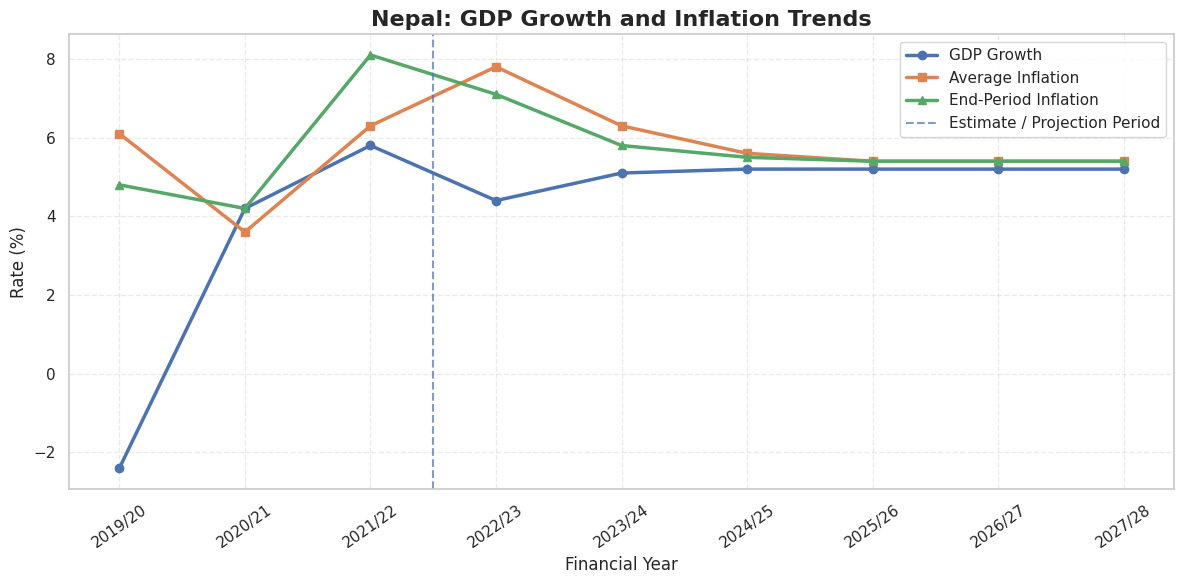

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    macro_df["Financial Year"],
    macro_df["GDP Growth"],
    marker="o",
    linewidth=2.5,
    label="GDP Growth"
)

ax.plot(
    macro_df["Financial Year"],
    macro_df["Inflation Average"],
    marker="s",
    linewidth=2.5,
    label="Average Inflation"
)

ax.plot(
    macro_df["Financial Year"],
    macro_df["Inflation End Period"],
    marker="^",
    linewidth=2.5,
    label="End-Period Inflation"
)

ax.axvline(
    x=2.5,
    linestyle="--",
    alpha=0.7,
    label="Estimate / Projection Period"
)

ax.set_title(
    "Nepal: GDP Growth and Inflation Trends",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Financial Year", fontsize=12)
ax.set_ylabel("Rate (%)", fontsize=12)

ax.legend()
ax.tick_params(axis="x", rotation=35)
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "data/dashboard/figure1_gdp_inflation_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

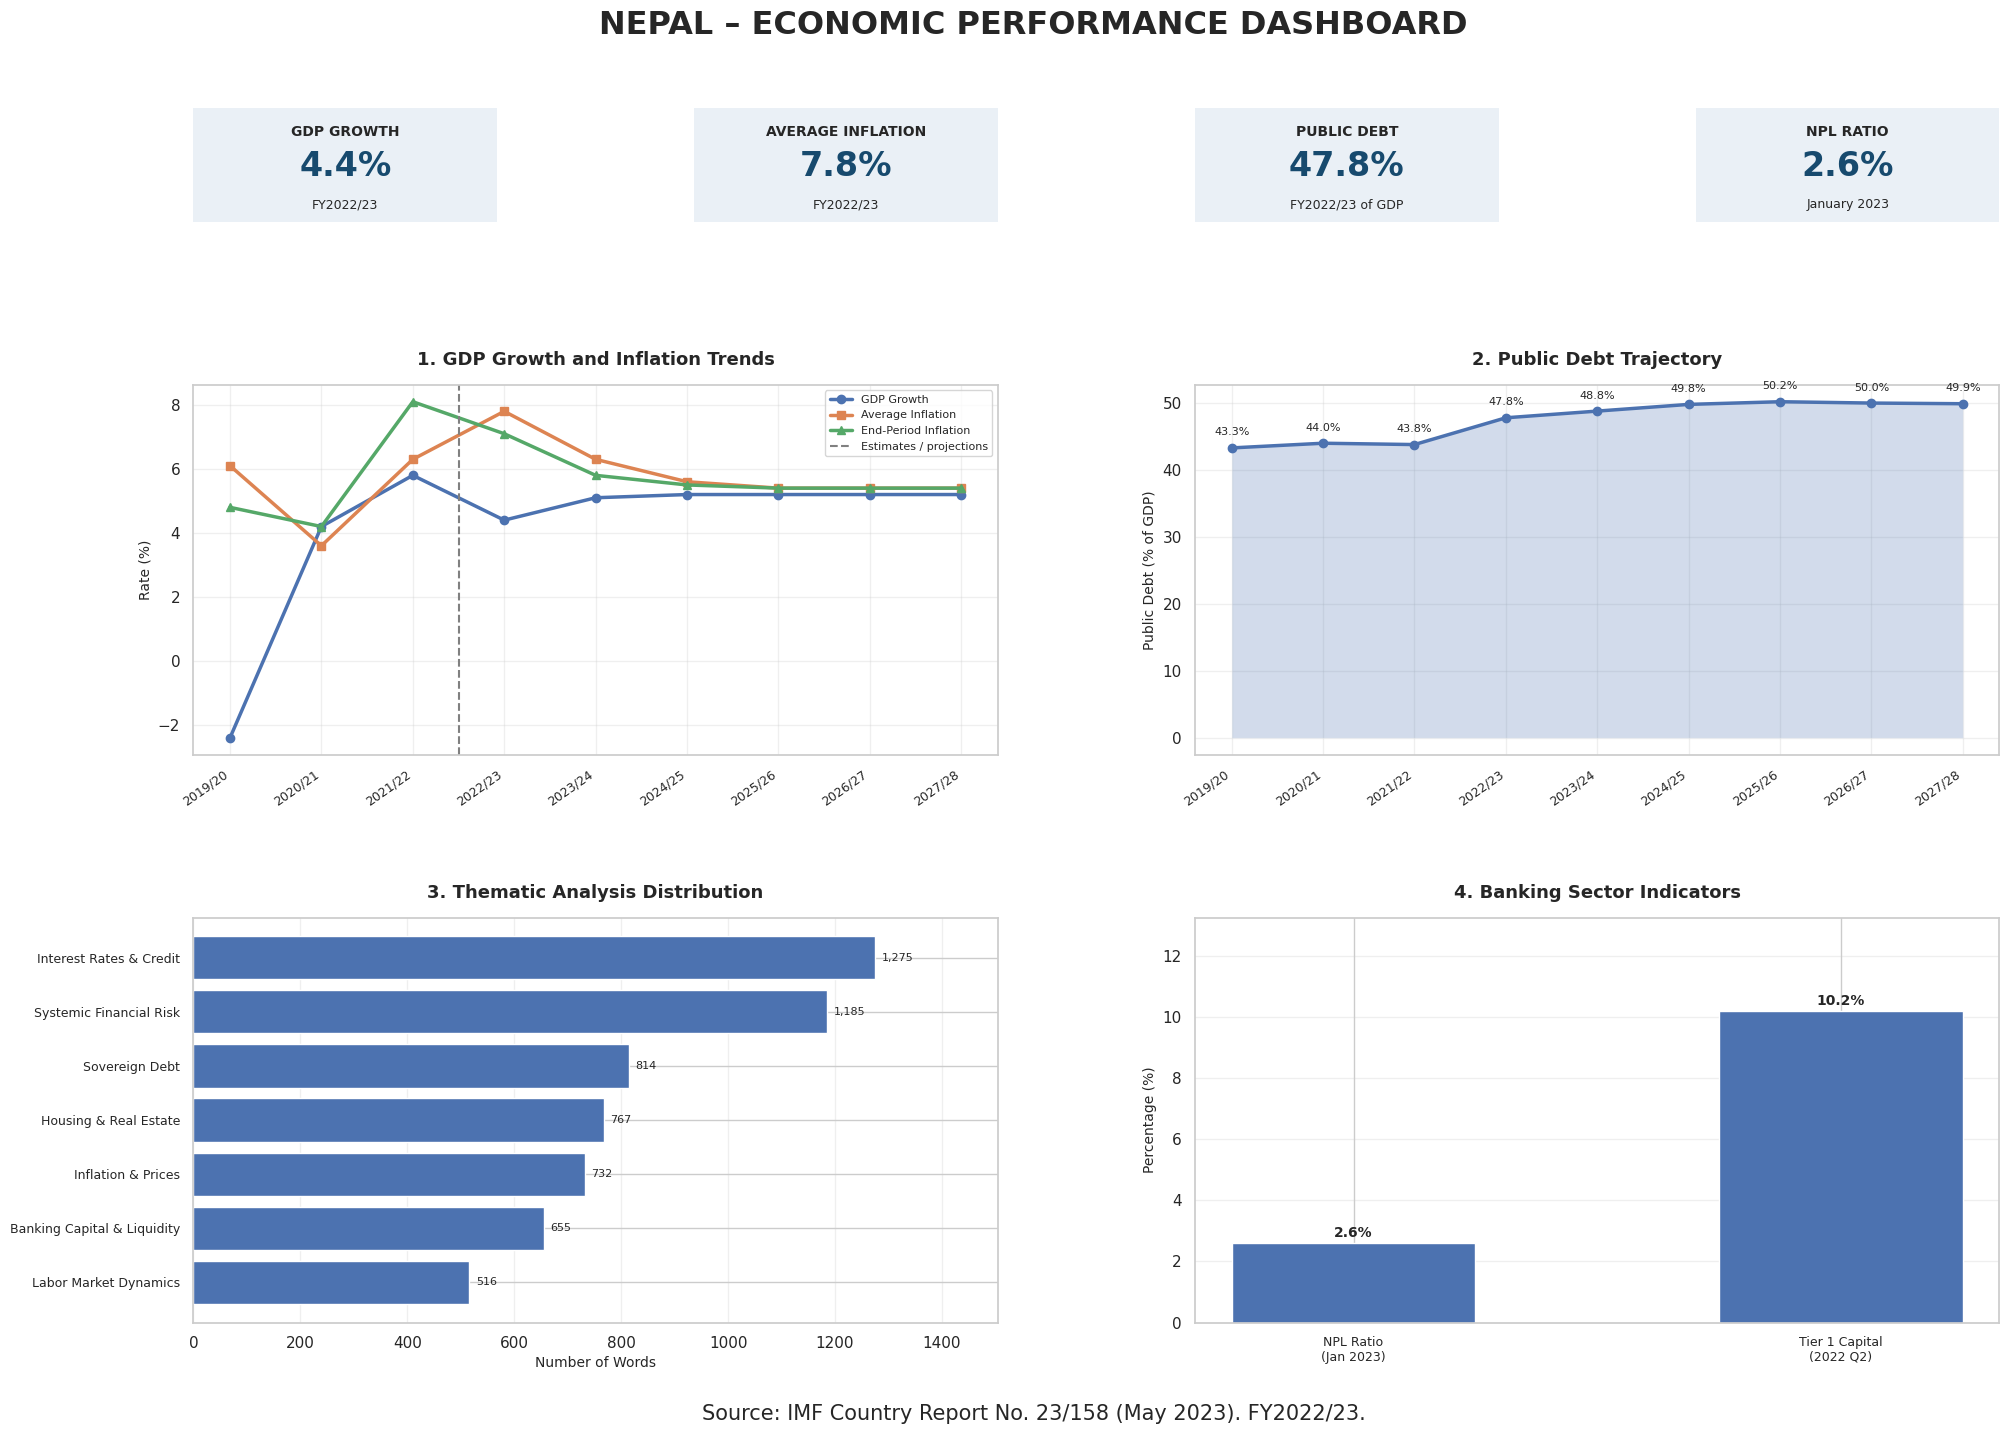

Corrected dashboard generated successfully.
Saved: data/dashboard/nepal_economic_dashboard.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import textwrap
import os

sns.set_theme(style="whitegrid")

os.makedirs("data/dashboard", exist_ok=True)

fig = plt.figure(figsize=(21, 15))

fig.suptitle(
    "NEPAL – ECONOMIC PERFORMANCE DASHBOARD",
    fontsize=23,
    fontweight="bold",
    y=0.975
)


gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.65, 2.1, 2.3],
    hspace=0.55,
    wspace=0.65
)

fig.subplots_adjust(
    left=0.10,
    right=0.96,
    top=0.91,
    bottom=0.10
)

kpis = [
    ("GDP GROWTH", "4.4%", "FY2022/23"),
    ("AVERAGE INFLATION", "7.8%", "FY2022/23"),
    ("PUBLIC DEBT", "47.8%", "FY2022/23 of GDP"),
    ("NPL RATIO", "2.6%", "January 2023")
]

for i, (label, value, period) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("#EAF0F6")
    ax.text(0.5, 0.75, label, ha="center",
            fontsize=10, fontweight="bold",
            transform=ax.transAxes)
    ax.text(0.5, 0.40, value, ha="center",
            fontsize=24, fontweight="bold",
            color="#174A6E", transform=ax.transAxes)
    ax.text(0.5, 0.12, period, ha="center",
            fontsize=9, transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

x = np.arange(len(macro_df))

ax1 = fig.add_subplot(gs[1, :2])

ax1.plot(x, macro_df["GDP Growth"],
         marker="o", linewidth=2.5, label="GDP Growth")

ax1.plot(x, macro_df["Inflation Average"],
         marker="s", linewidth=2.5, label="Average Inflation")

ax1.plot(x, macro_df["Inflation End Period"],
         marker="^", linewidth=2.5, label="End-Period Inflation")

ax1.axvline(2.5, linestyle="--", color="grey",
            label="Estimates / projections")

ax1.set_title("1. GDP Growth and Inflation Trends",
              fontsize=13, fontweight="bold", pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels(macro_df["Financial Year"],
                    rotation=35, ha="right", fontsize=9)
ax1.set_ylabel("Rate (%)", fontsize=10)
ax1.legend(fontsize=8, loc="best")
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[1, 2:])

ax2.fill_between(
    x,
    macro_df["Public Debt"].to_numpy(),
    alpha=0.25
)

ax2.plot(
    x,
    macro_df["Public Debt"],
    marker="o",
    linewidth=2.5
)

ax2.set_title("2. Public Debt Trajectory",
              fontsize=13, fontweight="bold", pad=14)
ax2.set_xticks(x)
ax2.set_xticklabels(macro_df["Financial Year"],
                    rotation=35, ha="right", fontsize=9)
ax2.set_ylabel("Public Debt (% of GDP)", fontsize=10)
ax2.grid(alpha=0.3)

for i, value in enumerate(macro_df["Public Debt"]):
    ax2.annotate(
        f"{value:.1f}%",
        (i, value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

ax3 = fig.add_subplot(gs[2, :2])

theme_sorted = theme_df.sort_values("word_count", ascending=True)

bars = ax3.barh(
    theme_sorted["theme"],
    theme_sorted["word_count"]
)

ax3.set_title("3. Thematic Analysis Distribution",
              fontsize=13, fontweight="bold", pad=14)
ax3.set_xlabel("Number of Words", fontsize=10)
ax3.tick_params(axis="y", labelsize=9)
ax3.set_xlim(0, theme_sorted["word_count"].max() * 1.18)
ax3.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    ax3.text(
        width + 12,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=8
    )

ax4 = fig.add_subplot(gs[2, 2:])

short_labels = [
    "NPL Ratio\n(Jan 2023)",
    "Tier 1 Capital\n(2022 Q2)"
]

banking_values = banking_df["Percentage"].to_numpy()

bars = ax4.bar(
    short_labels,
    banking_values,
    width=0.5
)

ax4.set_title("4. Banking Sector Indicators",
              fontsize=13, fontweight="bold", pad=14)
ax4.set_ylabel("Percentage (%)", fontsize=10)
ax4.set_ylim(0, max(banking_values) * 1.3)
ax4.tick_params(axis="x", labelsize=9)
ax4.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, banking_values):
    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.1f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

fig.text(
    0.5, 0.035,
    "Source: IMF Country Report No. 23/158 (May 2023). "
    "FY2022/23.",
    ha="center",
    fontsize=15
)

plt.savefig(
    "data/dashboard/nepal_economic_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Corrected dashboard generated successfully.")
print("Saved: data/dashboard/nepal_economic_dashboard.png")

In [ ]:
import json
import time
import pandas as pd
import re

benchmark_models = [
    "models/gemini-3.5-flash",
    "models/gemini-3.6-flash",
    "models/gemini-3.8-flash"
]

benchmark_prompt = f"""
Extract the following economic indicators for Nepal from the source.

Return ONLY valid JSON with these exact fields:
country_name
gdp_growth_forecast_pct
headline_inflation_rate_pct
central_bank_policy_rate_pct
non_performing_loan_ratio
unemployment_rate_pct
tier_1_capital_ratio

Use null when an indicator is not explicitly available.
Do not invent values.
Use the FY2022/23 GDP growth forecast and average inflation forecast.
Use the latest explicitly reported NPL and Tier 1 capital figures.

SOURCE:
{indicator_source}
"""

expected_values = {
    "country_name": "Nepal",
    "gdp_growth_forecast_pct": 4.4,
    "headline_inflation_rate_pct": 7.8,
    "central_bank_policy_rate_pct": None,
    "non_performing_loan_ratio": 2.6,
    "unemployment_rate_pct": None,
    "tier_1_capital_ratio": 10.2
}

benchmark_results = []

for model_name in benchmark_models:
    print("Testing:", model_name)

    start_time = time.time()

    try:
        response = client.models.generate_content(
            model=model_name,
            contents=benchmark_prompt
        )

        elapsed_time = round(time.time() - start_time, 2)

        response_text = response.text.strip()
        cleaned_text = re.sub(
            r"^```(?:json)?\s*|\s*```$",
            "",
            response_text,
            flags=re.IGNORECASE
        ).strip()

        extracted = json.loads(cleaned_text)

        required_fields = list(expected_values.keys())

        json_compliance = all(
            field in extracted for field in required_fields
        )

        correct_fields = sum(
            extracted.get(field) == expected_values[field]
            for field in required_fields
        )

        accuracy = round(
            correct_fields / len(required_fields) * 100, 2
        )

        benchmark_results.append({
            "Model": model_name,
            "JSON Compliance": "Pass" if json_compliance else "Fail",
            "Correct Fields": correct_fields,
            "Total Fields": len(required_fields),
            "Extraction Accuracy (%)": accuracy,
            "Response Time (seconds)": elapsed_time,
            "Output": extracted
        })

    except Exception as error:
        elapsed_time = round(time.time() - start_time, 2)

        benchmark_results.append({
            "Model": model_name,
            "JSON Compliance": "Fail",
            "Correct Fields": 0,
            "Total Fields": len(expected_values),
            "Extraction Accuracy (%)": 0,
            "Response Time (seconds)": elapsed_time,
            "Output": str(error)
        })

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df.to_csv(
    "data/dashboard/gemini_model_benchmark.csv",
    index=False
)

display(
    benchmark_df[
        [
            "Model",
            "JSON Compliance",
            "Correct Fields",
            "Total Fields",
            "Extraction Accuracy (%)",
            "Response Time (seconds)"
        ]
    ]
)

print("Benchmark completed.")

Testing: models/gemini-3.5-flash
Testing: models/gemini-3.6-flash
Testing: models/gemini-3.8-flash


,Model,JSON Compliance,Correct Fields,Total Fields,Extraction Accuracy (%),Response Time (seconds)
0,models/gemini-3.5-flash,Pass,6,7,85.71,16.16
1,models/gemini-3.6-flash,Pass,6,7,85.71,31.41
2,models/gemini-3.8-flash,Pass,4,7,57.14,357.60


Benchmark completed.


In [ ]:
comparison_rows = []

for result in benchmark_results:
    output = result["Output"]

    if isinstance(output, dict):
        for field, expected in expected_values.items():
            actual = output.get(field)

            comparison_rows.append({
                "Model": result["Model"],
                "Indicator": field,
                "Expected": expected,
                "Extracted": actual,
                "Correct": actual == expected
            })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

comparison_df.to_csv(
    "data/dashboard/benchmark_field_comparison.csv",
    index=False
)

,Model,Indicator,Expected,Extracted,Correct
0,models/gemini-3.5-flash,country_name,Nepal,Nepal,True
1,models/gemini-3.5-flash,gdp_growth_forecast_pct,4.4,4.4-4.5,False
2,models/gemini-3.5-flash,headline_inflation_rate_pct,7.8,7.8,True
3,models/gemini-3.5-flash,central_bank_policy_rate_pct,None,None,True
4,models/gemini-3.5-flash,non_performing_loan_ratio,2.6,2.6,True
5,models/gemini-3.5-flash,unemployment_rate_pct,None,None,True
6,models/gemini-3.5-flash,tier_1_capital_ratio,10.2,10.2,True
7,models/gemini-3.6-flash,country_name,Nepal,Nepal,True
8,models/gemini-3.6-flash,gdp_growth_forecast_pct,4.4,4.4-4.5,False
9,models/gemini-3.6-flash,headline_inflation_rate_pct,7.8,7.8,True


In [ ]:
import re
import numpy as np
import pandas as pd

def evaluate_value(actual, expected):
    if expected is None:
        return actual is None

    if actual is None:
        return False

    if isinstance(expected, str):
        return str(actual).strip().lower() == expected.lower()

    actual_text = str(actual).replace("%", "").strip()
    actual_text = actual_text.replace("–", "-").replace("—", "-")

    numbers = re.findall(r"-?\d+(?:\.\d+)?", actual_text)

    if not numbers:
        return False

    values = [float(number) for number in numbers]

    if len(values) == 1:
        return np.isclose(values[0], float(expected))

    if len(values) == 2:
        lower, upper = min(values), max(values)
        return lower <= float(expected) <= upper

    return False


semantic_results = []

for result in benchmark_results:
    output = result["Output"]

    if isinstance(output, dict):
        correct_fields = sum(
            evaluate_value(output.get(field), expected)
            for field, expected in expected_values.items()
        )

        semantic_results.append({
            "Model": result["Model"],
            "JSON Compliance": result["JSON Compliance"],
            "Correct Fields": correct_fields,
            "Total Fields": len(expected_values),
            "Semantic Accuracy (%)": round(
                correct_fields / len(expected_values) * 100, 2
            ),
            "Response Time (seconds)": result["Response Time (seconds)"]
        })

semantic_benchmark_df = pd.DataFrame(semantic_results)

display(semantic_benchmark_df)

semantic_benchmark_df.to_csv(
    "data/dashboard/semantic_model_benchmark.csv",
    index=False
)

,Model,JSON Compliance,Correct Fields,Total Fields,Semantic Accuracy (%),Response Time (seconds)
0,models/gemini-3.5-flash,Pass,7,7,100.0,16.16
1,models/gemini-3.6-flash,Pass,7,7,100.0,31.41
2,models/gemini-3.8-flash,Pass,7,7,100.0,357.60


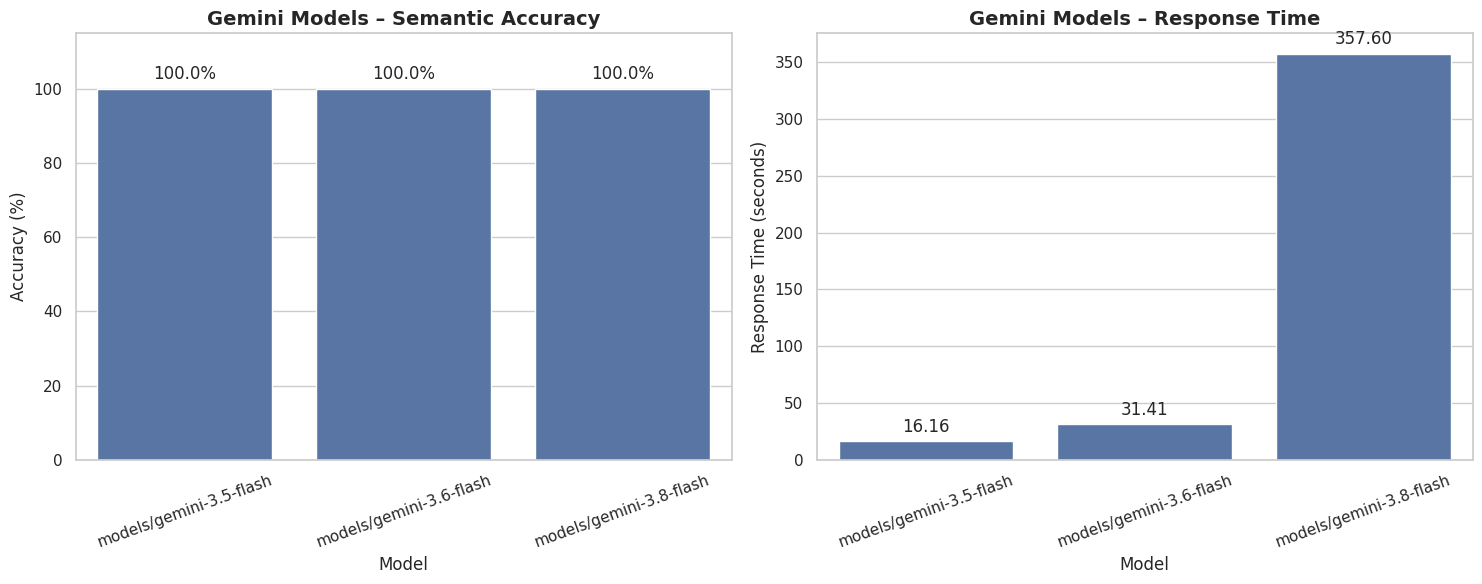

Benchmark visualisations saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

accuracy_plot = sns.barplot(
    data=semantic_benchmark_df,
    x="Model",
    y="Semantic Accuracy (%)",
    ax=axes[0]
)

axes[0].set_title(
    "Gemini Models – Semantic Accuracy",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 115)
axes[0].tick_params(axis="x", rotation=20)

for container in accuracy_plot.containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=4)

time_plot = sns.barplot(
    data=semantic_benchmark_df,
    x="Model",
    y="Response Time (seconds)",
    ax=axes[1]
)

axes[1].set_title(
    "Gemini Models – Response Time",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Response Time (seconds)")
axes[1].tick_params(axis="x", rotation=20)

for container in time_plot.containers:
    axes[1].bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()

plt.savefig(
    "data/dashboard/gemini_benchmark_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Benchmark visualisations saved successfully.")

In [ ]:
benchmark_findings = """
Gemini Flash Model Benchmarking

Three Gemini Flash models were evaluated using the same
Nepal IMF economic indicator extraction task.

All three models achieved valid JSON compliance and
100% semantic accuracy across seven evaluated fields.

Gemini 3.5 Flash:
Semantic accuracy: 100%
Response time: 16.16 seconds

Gemini 3.6 Flash:
Semantic accuracy: 100%
Response time: 31.41 seconds

Gemini 3.8 Flash:
Semantic accuracy: 100%
Response time: 357.60 seconds

Gemini 3.5 Flash demonstrated the shortest response time
while maintaining the same measured semantic accuracy.

These findings are based on one execution per model.
They should be interpreted as observed results rather
than statistically conclusive performance differences.
"""

with open(
    "data/dashboard/benchmark_findings.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(benchmark_findings)

print("Benchmark findings saved.")

Benchmark findings saved.


In [ ]:
import os

for root, dirs, files_list in os.walk("data"):
    level = root.replace("data", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(files_list):
        print(f"{indent}    {filename}")

data/
    nepal_chunks.csv
    nepal_chunks.json
    nepal_extracted_pages.json
    summaries/
        chunk_summaries.json
        nepal_all_29_summaries.json
        nepal_successful_summaries.json
    rag/
        nepal_chunk_metadata.json
        nepal_embeddings.npy
        nepal_faiss_index.bin
        nepal_rag_improved_results.json
        nepal_rag_npl_corrected.json
        nepal_rag_test_results.json
    backup/
        nepal_chunk_summaries.json
    thematic_analysis/
        nepal_all_thematic_findings.txt
        nepal_indicator_evaluation.txt
        nepal_indicators.json
        nepal_qualitative_analysis.json
        nepal_thematic_analysis.json
    consolidated/
        nepal_combined_summaries.txt
        nepal_final_executive_summary.txt
        nepal_group_summaries.json
    dashboard/
        banking_indicators.csv
        benchmark_field_comparison.csv
        benchmark_findings.txt
        figure1_gdp_inflation_trends.png
        gemini_benchmark_comparison.png


In [ ]:
import json

files_to_check = [
    "data/rag/nepal_rag_test_results.json",
    "data/rag/nepal_rag_improved_results.json",
    "data/rag/nepal_rag_npl_corrected.json"
]

for file_path in files_to_check:
    print("\n" + "=" * 70)
    print(file_path)

    with open(file_path, "r", encoding="utf-8") as file:
        result = json.load(file)

    print(json.dumps(result, indent=2, ensure_ascii=False)[:7000])


data/rag/nepal_rag_test_results.json
[
  {
    "question": "What was Nepal's non-performing loan ratio in January 2023?",
    "answer": "Based on the retrieved source passages, the specific non-performing loan (NPL) ratio for Nepal in January 2023 is not provided. The text only notes that \"non-performing loans (NPL) are increasing\" (IMF PDF pages 12–13). \n\nTherefore, the evidence in the provided passages is insufficient to answer the question."
  },
  {
    "question": "What was Nepal's public debt as a percentage of GDP in FY2021/22?",
    "answer": "Based on the retrieved passages from the report:\n\n1. **Net Present Value (PV) of External Debt:** The net present value of Nepal's external debt was estimated at **13.1 percent of GDP** in **FY2021/22** (IMF PDF pages 112–113).\n\n2. **Total Public Debt:** \n   * The text explicitly states that total public debt reached **44 percent of GDP in FY2020/21** (IMF PDF pages 111–112).\n   * In the statistical table on page 42 (IMF PDF pa

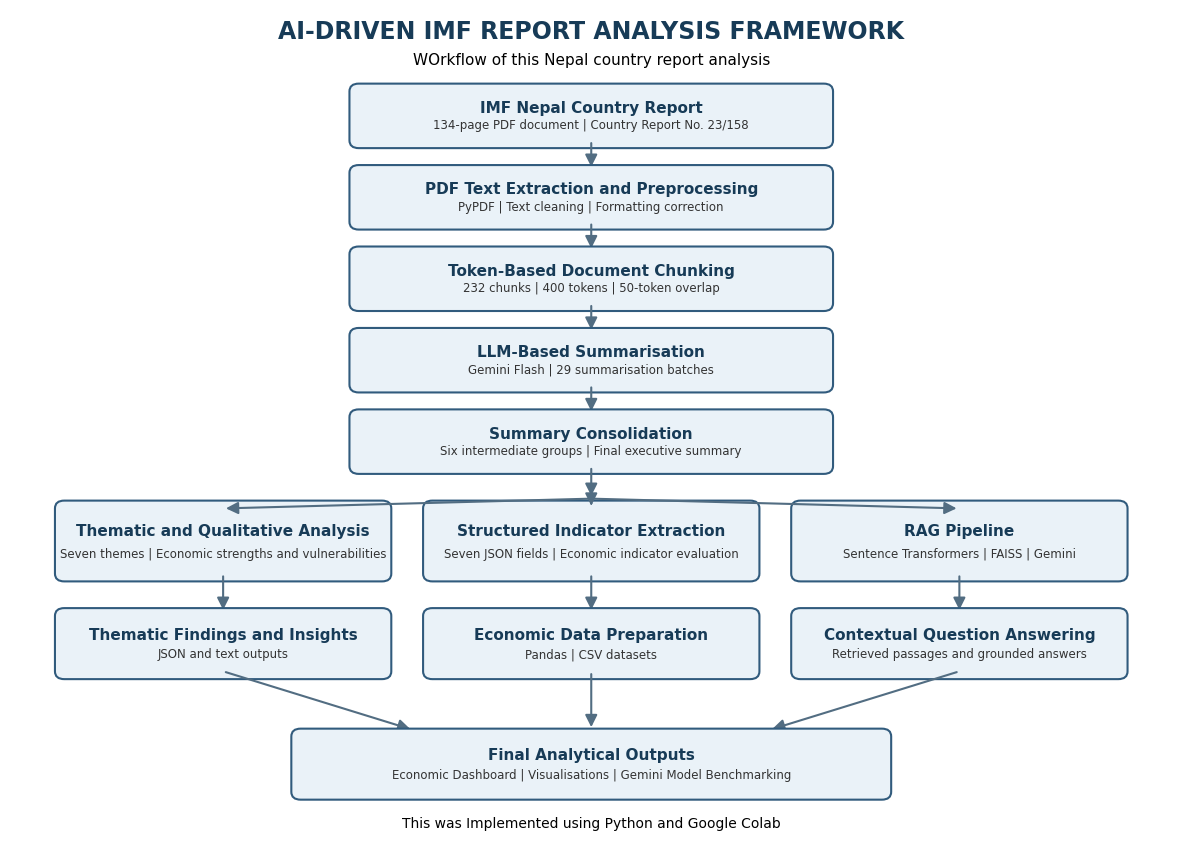

System architecture diagram generated successfully.
Saved: data/dashboard/figure1_system_architecture.png


In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

os.makedirs("data/dashboard", exist_ok=True)

fig, ax = plt.subplots(figsize=(15, 11))

ax.set_xlim(0, 15)
ax.set_ylim(0, 13)
ax.axis("off")

def draw_box(x, y, width, height, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="#315B7D",
        facecolor="#EAF2F8"
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height * 0.65,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#173B57"
    )

    if subtitle:
        ax.text(
            x + width / 2,
            y + height * 0.30,
            subtitle,
            ha="center",
            va="center",
            fontsize=8.5,
            color="#333333"
        )

def draw_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.5,
        color="#526D82"
    )

    ax.add_patch(arrow)

ax.text(
    7.5, 12.55,
    "AI-DRIVEN IMF REPORT ANALYSIS FRAMEWORK",
    ha="center",
    fontsize=17,
    fontweight="bold",
    color="#173B57"
)

ax.text(
    7.5, 12.15,
    "WOrkflow of this Nepal country report analysis",
    ha="center",
    fontsize=11,
    color="#000000"
)

draw_box(
    4.5, 11.0, 6, 0.75,
    "IMF Nepal Country Report",
    "134-page PDF document | Country Report No. 23/158"
)

draw_arrow(7.5, 11.0, 7.5, 10.55)

draw_box(
    4.5, 9.75, 6, 0.75,
    "PDF Text Extraction and Preprocessing",
    "PyPDF | Text cleaning | Formatting correction"
)

draw_arrow(7.5, 9.75, 7.5, 9.30)

draw_box(
    4.5, 8.50, 6, 0.75,
    "Token-Based Document Chunking",
    "232 chunks | 400 tokens | 50-token overlap"
)

draw_arrow(7.5, 8.50, 7.5, 8.05)

draw_box(
    4.5, 7.25, 6, 0.75,
    "LLM-Based Summarisation",
    "Gemini Flash | 29 summarisation batches"
)

draw_arrow(7.5, 7.25, 7.5, 6.80)

draw_box(
    4.5, 6.00, 6, 0.75,
    "Summary Consolidation",
    "Six intermediate groups | Final executive summary"
)

draw_arrow(7.5, 6.00, 7.5, 5.50)

draw_box(
    0.7, 4.35, 4.1, 1.0,
    "Thematic and Qualitative Analysis",
    "Seven themes | Economic strengths and vulnerabilities"
)

draw_box(
    5.45, 4.35, 4.1, 1.0,
    "Structured Indicator Extraction",
    "Seven JSON fields | Economic indicator evaluation"
)

draw_box(
    10.2, 4.35, 4.1, 1.0,
    "RAG Pipeline",
    "Sentence Transformers | FAISS | Gemini"
)

draw_arrow(7.5, 5.50, 2.75, 5.35)
draw_arrow(7.5, 5.50, 7.5, 5.35)
draw_arrow(7.5, 5.50, 12.25, 5.35)

draw_arrow(2.75, 4.35, 2.75, 3.75)
draw_arrow(7.5, 4.35, 7.5, 3.75)
draw_arrow(12.25, 4.35, 12.25, 3.75)

draw_box(
    0.7, 2.85, 4.1, 0.85,
    "Thematic Findings and Insights",
    "JSON and text outputs"
)

draw_box(
    5.45, 2.85, 4.1, 0.85,
    "Economic Data Preparation",
    "Pandas | CSV datasets"
)

draw_box(
    10.2, 2.85, 4.1, 0.85,
    "Contextual Question Answering",
    "Retrieved passages and grounded answers"
)

draw_arrow(2.75, 2.85, 5.2, 1.95)
draw_arrow(7.5, 2.85, 7.5, 1.95)
draw_arrow(12.25, 2.85, 9.8, 1.95)

draw_box(
    3.75, 1.0, 7.5, 0.85,
    "Final Analytical Outputs",
    "Economic Dashboard | Visualisations | Gemini Model Benchmarking"
)

ax.text(
    7.5, 0.45,
    "This was Implemented using Python and Google Colab",
    ha="center",
    fontsize=10,
    color="#000000"
)

plt.savefig(
    "data/dashboard/figure1_system_architecture.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("System architecture diagram generated successfully.")
print("Saved: data/dashboard/figure1_system_architecture.png")